# 05 · Fine-tuning de NLLB (français → bambara) avec LoRA

**But.** Adapter NLLB à nos ~3 000 paires de presse malienne pour qu'il traduise mieux le français vers le bambara.

**Point de départ** (notebook 03, 300 phrases de test) : BLEU 5,4 et chrF 27,4 pour fr → bam. Sur Colab, ton premier entraînement avait fait passer ces scores à environ **BLEU 14,0 et chrF 42,7** (même échantillon, même décodage).

### Les choix, expliqués

- **Un seul sens, fr → bam** : c'est le plus faible, et celui qui compte pour le projet.
- **LoRA** plutôt qu'un entraînement complet. Au lieu de modifier les 600 millions de paramètres du modèle, on y *ajoute* de toutes petites matrices (quelques pour cent du total) et on n'entraîne que celles-ci. Avantages : beaucoup moins de mémoire, plus rapide, et le modèle « oublie » moins ce qu'il savait déjà, ce qui compte avec si peu de données.
- **Évaluation identique au baseline** : mêmes phrases de test, même décodage, pour que la comparaison avant / après soit honnête.
- **Arrêt anticipé** : on surveille la *perte sur la validation* (une mesure d'erreur sur des phrases non utilisées pour apprendre). Si elle cesse de baisser, on s'arrête et on garde le meilleur point. Évite le *surapprentissage*, c'est-à-dire apprendre les exemples par cœur au lieu de généraliser.

| | |
|---|---|
| **Prérequis** | notebook 01 fait ; **GPU NVIDIA indispensable** (voir ci-dessous) |
| **Durée** | de quelques dizaines de minutes à plusieurs heures selon ta carte graphique |
| **Ce que tu obtiens** | l'adaptateur `models/nllb-fr-bam-lora/` et des scores comparés dans `results/` |

> **Carte de moins de 6 Go (par exemple 4 Go) ?** Le notebook passe tout seul en **mode économe** (`LOW_VRAM`) : le modèle de base, qui reste gelé pendant l'entraînement, est gardé en demi-précision (1,2 Go au lieu de 2,4 Go), la technique du *gradient checkpointing* recalcule certains résultats intermédiaires au lieu de les stocker (un peu plus lent, beaucoup moins de mémoire), et les lots sont minuscules (1 phrase à la fois, 16 lots accumulés). Ça devrait tenir dans 4 Go, mais c'est à confirmer sur ta machine ; l'entraînement sera plus lent que sur une carte plus grande.

> **Pas de GPU NVIDIA ?** Le fine-tuning sur processeur prendrait des heures voire des jours : le notebook s'arrête avec un message. Tu peux alors faire cette étape sur Google Colab (GPU gratuit) et récupérer le dossier `nllb-fr-bam-lora` dans `models/`. Pour seulement vérifier que le code tourne, mets `ALLOW_CPU = True` : le notebook n'utilisera alors que 64 phrases.

## 0. (Colab) Connecter Google Drive et préparer le projet

**Objectif.** Si tu fais cette étape sur Google Colab (plan B pour une petite carte), retrouver ton projet et tes données depuis ton Drive. Sur ton ordinateur (WSL), cette cellule ne fait rien.

**Ce que fait la cellule.** Si le notebook tourne sur Colab : monte ton Drive (une fenêtre te demande l'autorisation), installe les bibliothèques manquantes, décompresse `colab_05.zip` (qui contient `src/` et `data/processed/`) depuis le dossier Drive `nlp-bambara`, puis se place dans le projet.

**Ce que tu dois voir.** `Colab détecté` puis `Projet prêt : /content/nlp-bambara`. Dans WSL : `Hors Colab : rien à faire`.

> **Attention.** Sur Colab, choisis un GPU : *Exécution → Modifier le type d'exécution → T4 GPU*, et mets `colab_05.zip` dans le dossier `nlp-bambara` de ton Drive (ou change `DRIVE_DIR`).

In [1]:
import os
import subprocess
import sys
import zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
DRIVE_DIR = Path("/content/drive/MyDrive/nlp-bambara")   # dossier de ton Drive
PROJECT_ZIP = DRIVE_DIR / "colab_05.zip"
COLAB_ROOT = Path("/content/nlp-bambara")

if IN_COLAB:
    print("Colab détecté")
    from google.colab import drive
    drive.mount("/content/drive")

    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "peft", "sacrebleu", "sentencepiece", "accelerate"], check=True)

    if not PROJECT_ZIP.exists():
        raise FileNotFoundError(f"{PROJECT_ZIP} introuvable : mets colab_05.zip dans ce dossier de ton Drive.")
    COLAB_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(PROJECT_ZIP) as z:
        z.extractall(COLAB_ROOT)
    os.chdir(COLAB_ROOT)          # la cellule suivante cherche src/ à partir d'ici
    print("Projet prêt :", Path.cwd())
else:
    print("Hors Colab : rien à faire")

Hors Colab : rien à faire


## 1. Se repérer dans les dossiers

**Objectif.** Retrouver les dossiers du projet.

**Ce que fait la cellule.** Détecte la racine du projet et crée les dossiers manquants.

**Ce que tu dois voir.** Une ligne `Racine du projet : ...`.

In [2]:
import os
from pathlib import Path

# Ces deux réglages évitent des avertissements inutiles de Hugging Face.
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# Racine du projet = le dossier qui contient "data", "models", "results", "src"...
cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if not (ROOT / "src").exists():
    raise RuntimeError(
        f"Dossier du projet introuvable depuis {cwd}. "
        "Lance Jupyter avec bash lancer_jupyter.sh (ou depuis le dossier du projet)."
    )

DATA_RAW = ROOT / "data" / "raw"
DATA_PROC = ROOT / "data" / "processed"
MODELS = ROOT / "models"
RESULTS = ROOT / "results"
for folder in (DATA_RAW, DATA_PROC, MODELS, RESULTS):
    folder.mkdir(parents=True, exist_ok=True)

print("Racine du projet :", ROOT)

Racine du projet : /mnt/c/Users/RobotsMali-Victus/Desktop/nlp-bambara/nlp-bambara-wsl


## 2. Charger les données

**Objectif.** Récupérer les phrases d'entraînement, de validation et de test préparées au notebook 01.

**Ce que fait la cellule.** Lit `train.tsv`, `val.tsv` et `test.tsv` dans `data/processed/`. Si un fichier manque, la cellule s'arrête avec un message clair.

**Ce que tu dois voir.** `{'train': 2970, 'val': 1499, 'test': 1499}` (environ).

> **Attention.** Si un fichier est introuvable, lance d'abord le notebook 01.

In [3]:
import pandas as pd

for name in ("train.tsv", "val.tsv", "test.tsv"):
    if not (DATA_PROC / name).exists():
        raise FileNotFoundError(f"{DATA_PROC / name} introuvable : lance d'abord le notebook 01.")

train = pd.read_csv(DATA_PROC / "train.tsv", sep="\t", encoding="utf-8")
val = pd.read_csv(DATA_PROC / "val.tsv", sep="\t", encoding="utf-8")
test = pd.read_csv(DATA_PROC / "test.tsv", sep="\t", encoding="utf-8")
print({"train": len(train), "val": len(val), "test": len(test)})

{'train': 2970, 'val': 1499, 'test': 1499}


## 2 bis. Ajouter des données supplémentaires (facultatif)

**Objectif.** Entraîner sur plus de phrases que les ~3 000 paires du corpus de départ.

**Ce que fait la cellule.** Cherche un fichier `donnees_supplementaires.tsv` (colonnes `fr` et `bam`, séparées par une tabulation) dans `data/processed/` (ou dans ton dossier Drive sur Colab). S'il existe : nettoie les paires (vides, trop courtes, rapport de longueur absurde, doublons), **retire toute phrase présente dans la validation ou le test**, puis les ajoute à `train` **en mémoire**. Aucun fichier n'est modifié. S'il n'existe pas, la cellule n'ajoute rien.

**Ce que tu dois voir.** `N phrases d'entraînement + M ajoutées`, ou `Aucune donnée supplémentaire`.

> **Attention.** Des paires mal alignées ou du bambara bruité *dégradent* le modèle. Vérifie aussi la licence de tes données (le corpus d'origine est CC BY-NC). Plus de données veut dire un entraînement plus long.

In [4]:
EXTRA_NAME = "donnees_supplementaires.tsv"
EXTRA_PATH = (DRIVE_DIR if IN_COLAB else DATA_PROC) / EXTRA_NAME

if EXTRA_PATH.exists():
    extra = pd.read_csv(EXTRA_PATH, sep="\t", encoding="utf-8")
    if not {"fr", "bam"} <= set(extra.columns):
        raise ValueError(f"{EXTRA_PATH} doit avoir les colonnes 'fr' et 'bam' (trouvé : {list(extra.columns)}).")
    n0 = len(extra)
    extra = extra[["fr", "bam"]].dropna().astype(str)
    extra["fr"], extra["bam"] = extra["fr"].str.strip(), extra["bam"].str.strip()

    # nettoyage simple : trop court, ou longueurs très déséquilibrées (souvent un mauvais alignement)
    ok = (extra["fr"].str.len() >= 3) & (extra["bam"].str.len() >= 3)
    ratio = extra["fr"].str.len() / extra["bam"].str.len().clip(lower=1)
    extra = extra[ok & ratio.between(0.25, 4.0)]

    # ne jamais apprendre sur des phrases de validation ou de test
    interdit_fr = set(val["fr"]) | set(test["fr"])
    interdit_bam = set(val["bam"]) | set(test["bam"])
    extra = extra[~extra["fr"].isin(interdit_fr) & ~extra["bam"].isin(interdit_bam)]

    n_before = len(train)
    train = pd.concat([train, extra], ignore_index=True).drop_duplicates(subset=["fr", "bam"]).reset_index(drop=True)
    print(f"{n_before} phrases d'entraînement + {len(train) - n_before} ajoutées "
          f"(sur {n0} lues dans {EXTRA_NAME}) = {len(train)}")
else:
    print(f"Aucune donnée supplémentaire ({EXTRA_PATH} introuvable) : entraînement sur le corpus de départ.")

Aucune donnée supplémentaire (/mnt/c/Users/RobotsMali-Victus/Desktop/nlp-bambara/nlp-bambara-wsl/data/processed/donnees_supplementaires.tsv introuvable) : entraînement sur le corpus de départ.


## 3. Détecter le matériel

**Objectif.** Savoir si un GPU NVIDIA est disponible et de quelle mémoire on dispose.

**Ce que fait la cellule.** Interroge PyTorch (nom de la carte, mémoire vidéo).

**Ce que tu dois voir.** Le nom de ta carte et sa mémoire, par exemple `GPU détecté : NVIDIA GeForce RTX 3060 (12.0 Go de mémoire vidéo)`.

In [5]:
import torch

if torch.cuda.is_available():
    device = "cuda"
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
    print(f"GPU détecté : {gpu_name} ({vram_gb:.1f} Go de mémoire vidéo)")
else:
    device = "cpu"
    vram_gb = 0.0
    print("Aucun GPU utilisable : le calcul se fera sur le processeur (CPU), beaucoup plus lentement.")
    print("Si tu as une carte NVIDIA, relance bash installer.sh et choisis l'option NVIDIA.")
print("PyTorch :", torch.__version__, "| CUDA compilée :", torch.version.cuda)

# Taille des lots pour traduire : prudente selon la mémoire vidéo disponible.
if device == "cuda":
    TRANSLATE_BATCH = 32 if vram_gb >= 8 else 16 if vram_gb >= 4 else 8
else:
    TRANSLATE_BATCH = 8

GPU détecté : NVIDIA GeForce RTX 2050 (4.0 Go de mémoire vidéo)
PyTorch : 2.14.1+cu126 | CUDA compilée : 12.6


## 4. Garde-fou : pas d'entraînement sur processeur

**Objectif.** Éviter de lancer par erreur un calcul qui durerait des heures.

**Ce que fait la cellule.** Si aucun GPU n'est détecté, la cellule s'arrête avec une explication, sauf si tu as mis `ALLOW_CPU = True`.

**Ce que tu dois voir.** Rien ne s'affiche si un GPU est détecté.

> **Attention.** Même avec `ALLOW_CPU = True`, le notebook ne s'entraîne que sur 64 phrases : c'est juste un test technique, le modèle obtenu ne vaut rien.

In [6]:
ALLOW_CPU = False   # True = essai technique sur processeur (64 phrases seulement)

if device == "cpu" and not ALLOW_CPU:
    raise RuntimeError(
        "Aucun GPU NVIDIA détecté : le fine-tuning prendrait des heures sur processeur.\n"
        "Options : (1) faire cette étape sur Google Colab puis copier le dossier nllb-fr-bam-lora dans models/ ;\n"
        "(2) vérifier l'installation avec verifier_installation.py ;\n"
        "(3) mettre ALLOW_CPU = True pour un simple test technique."
    )

## 5. Régler les paramètres

**Objectif.** Fixer les valeurs qui contrôlent l'entraînement. C'est ici qu'on expérimente.

**Ce que fait la cellule.** Voici ce que chaque réglage veut dire :

- `EPOCHS` : nombre de passages complets sur les données d'entraînement (une *époque* = tout le jeu vu une fois).
- `LR` (taux d'apprentissage) : la taille des pas de correction. Trop grand, l'entraînement diverge ; trop petit, il n'apprend presque rien. Pour LoRA, des valeurs plus grandes que d'habitude sont normales.
- `LORA_R` : la « taille » des petites matrices ajoutées (plus grand = plus de capacité d'apprentissage, plus de mémoire).
- `BATCH` et `ACCUM` : combien de phrases on traite à la fois, et sur combien de lots on accumule la correction. Le produit `BATCH × ACCUM` (= 16) est le *lot effectif*. Le notebook choisit des valeurs prudentes selon ta mémoire vidéo.
- `MAX_LEN` : longueur maximale en jetons ; au-delà, la phrase est coupée.
- `LOW_VRAM` : mode économe, activé automatiquement sur les cartes de moins de 6 Go (voir l'introduction du notebook).

**Ce que tu dois voir.** Une ligne qui résume les valeurs retenues.

> **Attention.** Si tu obtiens plus tard l'erreur **CUDA out of memory**, c'est que la mémoire vidéo est insuffisante : diminue `BATCH` (par exemple 4, 2 ou 1) et augmente `ACCUM` pour que `BATCH × ACCUM` reste 16.

In [7]:
MODEL_NAME = "facebook/nllb-200-distilled-600M"
FR, BAM = "fra_Latn", "bam_Latn"

MAX_LEN = 128
EPOCHS = 4
LR = 5e-4
LORA_R = 32
LORA_ALPHA = 64
LIMIT = 300 if device == "cuda" else 40          # phrases de test pour l'évaluation
TRAIN_SUBSET = None if device == "cuda" else 64  # sur processeur : essai technique

# Tailles de lots prudentes selon la mémoire vidéo (lot effectif = BATCH x ACCUM = 16).
if vram_gb >= 10:
    BATCH, ACCUM, EVAL_BATCH = 8, 2, 16
elif vram_gb >= 6:
    BATCH, ACCUM, EVAL_BATCH = 4, 4, 8
else:
    BATCH, ACCUM, EVAL_BATCH = 1, 16, 2   # petite carte (4 Go) : lot minimal, accumulé sur 16

# Mode économe pour les petites cartes (moins de 6 Go de mémoire vidéo).
LOW_VRAM = (device == "cuda") and vram_gb < 6
if LOW_VRAM:
    print("Mode économe activé (carte de moins de 6 Go) : base en demi-précision + gradient checkpointing.")

if TRAIN_SUBSET:
    train = train.head(TRAIN_SUBSET)
    val = val.head(TRAIN_SUBSET)

print(f"{len(train)} phrases d'entraînement | {EPOCHS} époques | lot {BATCH} x {ACCUM} | lr {LR} | LoRA r={LORA_R}")

Mode économe activé (carte de moins de 6 Go) : base en demi-précision + gradient checkpointing.
2970 phrases d'entraînement | 4 époques | lot 1 x 16 | lr 0.0005 | LoRA r=32


## 6. Charger NLLB et ajouter LoRA

**Objectif.** Préparer le modèle : on charge NLLB, puis on y branche les petites matrices LoRA qui seront seules entraînées.

**Ce que fait la cellule.** Télécharge NLLB si besoin (environ 2,5 Go au premier lancement). En mode économe, le modèle de base est converti en demi-précision. Applique ensuite la configuration LoRA aux couches d'attention (`q_proj`, `k_proj`, `v_proj`, `out_proj`) et aux couches denses (`fc1`, `fc2`), puis affiche la part de paramètres réellement entraînés.

**Ce que tu dois voir.** Une ligne du type `trainable params: ... || all params: ... || trainable%: ...` : seuls quelques pour cent du modèle sont entraînés.

> **Attention.** La première exécution est longue (téléchargement). Le modèle est ensuite gardé en cache dans `~/.cache/huggingface`.

In [8]:
import torch
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
from transformers import logging as hf_logging
from peft import LoraConfig, TaskType, get_peft_model

hf_logging.set_verbosity_error()

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, src_lang=FR, tgt_lang=BAM)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
if LOW_VRAM:
    # Mode économe : le modèle de base, gelé, passe en demi-précision (1,2 Go au lieu de 2,4 Go)
    # avant d'être envoyé sur la carte. Les petites matrices LoRA restent, elles, en précision normale.
    model = model.half()

lora = LoraConfig(
    task_type=TaskType.SEQ_2_SEQ_LM,
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "out_proj", "fc1", "fc2"],
)
model = get_peft_model(model, lora)
for param in model.parameters():
    if param.requires_grad:
        param.data = param.data.float()   # les paramètres entraînés restent en précision normale
model.print_trainable_parameters()

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

trainable params: 17,301,504 || all params: 632,375,296 || trainable%: 2.7360


## 7. Transformer les phrases en nombres

**Objectif.** Convertir le texte en jetons (nombres) que le modèle sait lire, et vérifier qu'on ne coupe pas trop de phrases.

**Ce que fait la cellule.** Pour chaque paire, le tokenizer produit les jetons de la phrase française (entrée) et de la phrase bambara (cible). Puis la cellule compte combien de phrases atteignent `MAX_LEN` et sont donc tronquées.

**Ce que tu dois voir.** Deux lignes, une pour l'entrée et une pour la sortie : la longueur médiane en jetons (autour de 40 à 60) et le nombre de phrases coupées (quelques-unes au plus).

> **Attention.** Si beaucoup de phrases sont coupées (plus de quelques pour cent), augmente `MAX_LEN`.

In [9]:
from datasets import Dataset

def preprocess(batch):
    return tokenizer(batch["fr"], text_target=batch["bam"], max_length=MAX_LEN, truncation=True)

def to_dataset(df):
    ds = Dataset.from_pandas(df[["fr", "bam"]], preserve_index=False)
    return ds.map(preprocess, batched=True, remove_columns=["fr", "bam"])

train_ds, val_ds = to_dataset(train), to_dataset(val)

lens_in = sorted(len(x) for x in train_ds["input_ids"])
lens_out = sorted(len(x) for x in train_ds["labels"])
print(f"entrée : médiane {lens_in[len(lens_in)//2]} jetons, coupées : {sum(l >= MAX_LEN for l in lens_in)}")
print(f"sortie : médiane {lens_out[len(lens_out)//2]} jetons, coupées : {sum(l >= MAX_LEN for l in lens_out)}")

Map:   0%|          | 0/2970 [00:00<?, ? examples/s]

Map:   0%|          | 0/1499 [00:00<?, ? examples/s]

entrée : médiane 34 jetons, coupées : 12
sortie : médiane 36 jetons, coupées : 30


## 8. Entraîner

**Objectif.** Faire apprendre au modèle, en surveillant l'erreur sur la validation à la fin de chaque époque.

**Ce que fait la cellule.** Configure l'entraîneur (`Seq2SeqTrainer`) : calcul en demi-précision `fp16` pour aller plus vite, montée progressive du taux d'apprentissage au début (*warmup*, 5 % des pas), évaluation et sauvegarde à chaque époque, retour automatique au meilleur point, et arrêt anticipé si la perte de validation ne s'améliore pas pendant 2 époques. Puis lance `trainer.train()`.

**Ce que tu dois voir.** Une barre de progression et, à chaque époque, un tableau avec `Training Loss` et `Validation Loss`. La perte de validation doit **baisser** (par exemple 2,39 → 2,22 → 2,15 → 2,12 lors de ton premier essai).

> **Attention.** Cette cellule est la plus longue. Ne ferme pas le notebook et branche ton ordinateur sur secteur. Si la perte de validation remonte alors que celle d'entraînement baisse, c'est du surapprentissage.

In [10]:
import dataclasses
import math

from transformers import (DataCollatorForSeq2Seq, EarlyStoppingCallback,
                          Seq2SeqTrainer, Seq2SeqTrainingArguments)

# Montée en charge du taux d'apprentissage : 5 % des pas d'entraînement.
steps_per_epoch = math.ceil(len(train_ds) / (BATCH * ACCUM))
WARMUP = max(1, int(0.05 * steps_per_epoch * EPOCHS))
print(f"{steps_per_epoch} pas par époque, {WARMUP} pas de montée en charge")

training_kwargs = dict(
    output_dir=str(MODELS / "checkpoints"),
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH,
    per_device_eval_batch_size=EVAL_BATCH,
    gradient_accumulation_steps=ACCUM,
    learning_rate=LR,
    warmup_steps=WARMUP,
    lr_scheduler_type="linear",
    fp16=(device == "cuda"),
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_steps=25,
    report_to="none",
    remove_unused_columns=False,
    label_names=["labels"],
    dataloader_num_workers=0,        # 0 = plus simple et plus sûr
)
if device == "cpu":
    training_kwargs["use_cpu"] = True
if LOW_VRAM:
    training_kwargs["gradient_checkpointing"] = True
    training_kwargs["gradient_checkpointing_kwargs"] = {"use_reentrant": False}

# Si une autre version de transformers ne connaît pas un argument, on l'ignore en le signalant.
known = {f.name for f in dataclasses.fields(Seq2SeqTrainingArguments)}
dropped = [k for k in training_kwargs if k not in known]
if dropped:
    print("Arguments ignorés (inconnus de cette version) :", dropped)
args = Seq2SeqTrainingArguments(**{k: v for k, v in training_kwargs.items() if k in known})

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=-100),
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
trainer.train()

186 pas par époque, 37 pas de montée en charge


/mnt/c/Users/RobotsMali-Victus/Desktop/nlp-bambara/nlp-bambara-wsl/.venv/lib/python3.12/site-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)
/mnt/c/Users/RobotsMali-Victus/Desktop/nlp-bambara/nlp-bambara-wsl/.venv/lib/python3.12/site-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing_kwargs` is deprecated and will be removed in v6. Use `activation_checkpointing_kwargs` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


{'loss': '59.62', 'grad_norm': '13.4', 'learning_rate': '0.0003243', 'epoch': '0.1347'}
{'loss': '48.64', 'grad_norm': '11.47', 'learning_rate': '0.0004915', 'epoch': '0.2694'}
{'loss': '47.17', 'grad_norm': '13.25', 'learning_rate': '0.0004738', 'epoch': '0.404'}
{'loss': '45.72', 'grad_norm': '13.22', 'learning_rate': '0.0004562', 'epoch': '0.5387'}
{'loss': '44.48', 'grad_norm': '11.69', 'learning_rate': '0.0004385', 'epoch': '0.6734'}
{'loss': '43.55', 'grad_norm': '14.25', 'learning_rate': '0.0004208', 'epoch': '0.8081'}
{'loss': '38.96', 'grad_norm': '14.81', 'learning_rate': '0.0003501', 'epoch': '1.345'}
{'loss': '36.72', 'grad_norm': '13.94', 'learning_rate': '0.0003324', 'epoch': '1.479'}
{'eval_loss': '2.246', 'eval_runtime': '64.35', 'eval_samples_per_second': '23.29', 'eval_steps_per_second': '11.65', 'epoch': '2'}


/mnt/c/Users/RobotsMali-Victus/Desktop/nlp-bambara/nlp-bambara-wsl/.venv/lib/python3.12/site-packages/peft/utils/other.py:1617: UserWarning: Unable to fetch remote file due to the following error [Errno -3] Temporary failure in name resolution - silently ignoring the lookup for the file config.json in facebook/nllb-200-distilled-600M.
  warnings.warn(
/mnt/c/Users/RobotsMali-Victus/Desktop/nlp-bambara/nlp-bambara-wsl/.venv/lib/python3.12/site-packages/peft/utils/save_and_load.py:364: UserWarning: Could not find a config file in facebook/nllb-200-distilled-600M - will assume that the vocabulary was not modified.
  warnings.warn(


{'loss': '36.4', 'grad_norm': '16.08', 'learning_rate': '0.0002617', 'epoch': '2.016'}
{'loss': '33.55', 'grad_norm': '16.61', 'learning_rate': '0.000244', 'epoch': '2.151'}
{'loss': '34.44', 'grad_norm': '18.79', 'learning_rate': '0.0002263', 'epoch': '2.286'}
{'loss': '32.83', 'grad_norm': '15.92', 'learning_rate': '0.0002086', 'epoch': '2.42'}
{'loss': '33.59', 'grad_norm': '17.88', 'learning_rate': '0.0001909', 'epoch': '2.555'}
{'loss': '34.05', 'grad_norm': '20.67', 'learning_rate': '0.0001733', 'epoch': '2.69'}
{'loss': '35.11', 'grad_norm': '17.81', 'learning_rate': '0.0001556', 'epoch': '2.824'}
{'loss': '34.69', 'grad_norm': '16.04', 'learning_rate': '0.0001379', 'epoch': '2.959'}
{'eval_loss': '2.18', 'eval_runtime': '62.47', 'eval_samples_per_second': '23.99', 'eval_steps_per_second': '12.01', 'epoch': '3'}
{'loss': '31.86', 'grad_norm': '16.98', 'learning_rate': '0.0001202', 'epoch': '3.092'}
{'loss': '31.53', 'grad_norm': '18.63', 'learning_rate': '0.0001025', 'epoch': '3

TrainOutput(global_step=744, training_loss=37.60383605957031, metrics={'train_runtime': 4331.4986, 'train_samples_per_second': 2.743, 'train_steps_per_second': 0.172, 'train_loss': 37.60383605957031, 'epoch': 4.0})

## 9. Courbes de perte

**Objectif.** Voir d'un coup d'œil si l'entraînement s'est bien passé.

**Ce que fait la cellule.** Trace la perte d'entraînement et la perte de validation, sauvegarde l'image dans `results/`, puis affiche la perte de validation à la fin de chaque époque.

**Ce que tu dois voir.** Deux courbes qui descendent. La courbe de validation doit rester proche de celle d'entraînement. Un tableau `epoch` / `eval_loss`.

> **Attention.** La colonne de gauche du tableau (`index`) est un numéro de ligne du journal d'entraînement, **pas** un numéro de pas : ne t'en préoccupe pas.

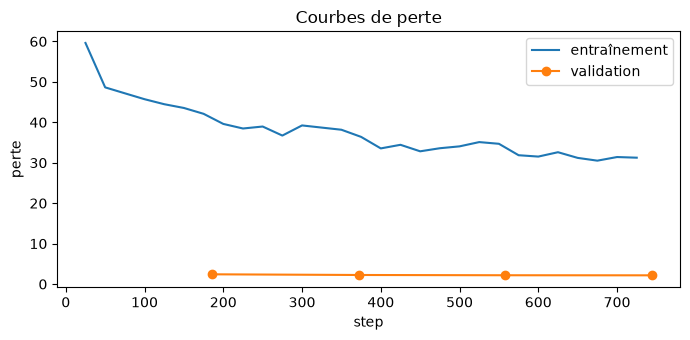

,epoch,eval_loss
7,1.0,2.412847
15,2.0,2.245719
24,3.0,2.179743
32,4.0,2.161543


In [11]:
import matplotlib.pyplot as plt

log = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(figsize=(7, 3.5))
if "loss" in log:
    log.dropna(subset=["loss"]).plot(x="step", y="loss", ax=ax, label="entraînement")
log.dropna(subset=["eval_loss"]).plot(x="step", y="eval_loss", ax=ax, marker="o", label="validation")
ax.set_ylabel("perte"); ax.set_title("Courbes de perte")
plt.tight_layout()
plt.savefig(RESULTS / "finetune_loss.png", dpi=150)
plt.show()
log.dropna(subset=["eval_loss"])[["epoch", "eval_loss"]]

## 10. Sauvegarder l'adaptateur et fusionner

**Objectif.** Conserver le résultat de l'entraînement sur le disque, puis préparer le modèle pour traduire.

**Ce que fait la cellule.** Enregistre l'adaptateur LoRA (quelques dizaines de Mo) dans `models/nllb-fr-bam-lora/`. C'est ce dossier qu'utiliseront les notebooks 04 et 06. Puis libère la mémoire (modèle d'entraînement, optimiseur), recharge un modèle propre, y applique l'adaptateur et le *fusionne* : il devient un modèle ordinaire, plus rapide pour traduire.

**Ce que tu dois voir.** Un message `Adaptateur sauvegardé : .../models/nllb-fr-bam-lora`. Vérifie dans l'explorateur que le dossier existe.

> **Attention.** **Sauvegarde ce dossier** : c'est le fruit de ton entraînement. Le copier sur une clé USB ou un cloud t'évite de tout refaire en cas de problème.

In [12]:
ADAPTER_DIR = MODELS / "nllb-fr-bam-lora"
trainer.save_model(str(ADAPTER_DIR))
tokenizer.save_pretrained(str(ADAPTER_DIR))
print("Adaptateur sauvegardé :", ADAPTER_DIR)

# On libère tout le matériel d'entraînement (modèle, optimiseur...), puis on recharge un modèle propre
# avec l'adaptateur fusionné : plus sûr, et indispensable sur une carte de 4 Go.
import gc
from peft import PeftModel

del trainer, model
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
model = PeftModel.from_pretrained(model, str(ADAPTER_DIR)).merge_and_unload()
if device == "cuda":
    model = model.half()      # fp16 d'abord sur le processeur : évite un pic de mémoire vidéo
model = model.to(device)
model.eval()

Adaptateur sauvegardé : /mnt/c/Users/RobotsMali-Victus/Desktop/nlp-bambara/nlp-bambara-wsl/models/nllb-fr-bam-lora


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

M2M100ForConditionalGeneration(
  (model): M2M100Model(
    (shared): M2M100ScaledWordEmbedding(256206, 1024, padding_idx=1)
    (encoder): M2M100Encoder(
      (embed_tokens): M2M100ScaledWordEmbedding(256206, 1024, padding_idx=1)
      (embed_positions): M2M100SinusoidalPositionalEmbedding()
      (layers): ModuleList(
        (0-11): 12 x M2M100EncoderLayer(
          (self_attn): M2M100Attention(
            (k_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (v_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (q_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (out_proj): Linear(in_features=1024, out_features=1024, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
          (activation_fn): ReLU()
          (fc1): Linear(in_features=1024, out_features=4096, bias=True)
          (fc2): Linear(in_features=4096, out_features=1024, bias=Tr

### Copie de l'adaptateur sur Google Drive (Colab seulement)

**Ce que fait la cellule.** Sur Colab, copie `models/nllb-fr-bam-lora/` dans ton dossier Drive `nlp-bambara`, pour ne rien perdre si Colab se déconnecte. Dans WSL, elle ne fait rien.

In [13]:
import shutil

if IN_COLAB:
    dest = DRIVE_DIR / "nllb-fr-bam-lora"
    shutil.copytree(ADAPTER_DIR, dest, dirs_exist_ok=True)
    print("Copié sur Drive :", dest)
else:
    print("Hors Colab : l'adaptateur est déjà dans", ADAPTER_DIR)

Hors Colab : l'adaptateur est déjà dans /mnt/c/Users/RobotsMali-Victus/Desktop/nlp-bambara/nlp-bambara-wsl/models/nllb-fr-bam-lora


## 11. Évaluer sur les mêmes phrases que le baseline

**Objectif.** Mesurer le gain, avec exactement les mêmes phrases de test et le même décodage que dans le notebook 03.

**Ce que fait la cellule.** Définit la même fonction de traduction qu'au notebook 03 (4 faisceaux), traduit `LIMIT` phrases du test, et affiche la durée.

**Ce que tu dois voir.** Une ligne `300 phrases traduites en N s`.

In [14]:
import time

def translate(texts, src, tgt, batch_size=None, num_beams=4, max_new_tokens=256):
    batch_size = batch_size or TRANSLATE_BATCH
    tokenizer.src_lang = src
    order = sorted(range(len(texts)), key=lambda i: len(texts[i]))
    outputs = [None] * len(texts)
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        batch = [texts[i] for i in idx]
        enc = tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=256).to(device)
        with torch.no_grad():
            generated = model.generate(
                **enc,
                forced_bos_token_id=tokenizer.convert_tokens_to_ids(tgt),
                num_beams=num_beams,
                max_new_tokens=max_new_tokens,
            )
        for i, text in zip(idx, tokenizer.batch_decode(generated, skip_special_tokens=True)):
            outputs[i] = text
    return outputs

subset = test.head(LIMIT) if LIMIT else test
t0 = time.time()
hyp_ft = translate(subset["fr"].tolist(), FR, BAM)
print(f"{len(subset)} phrases traduites en {time.time() - t0:.0f} s")

300 phrases traduites en 69 s


## 12. Comparer avant / après

**Objectif.** Chiffrer le progrès du fine-tuning.

**Ce que fait la cellule.** Calcule BLEU et chrF du modèle fine-tuné, puis les compare à la ligne « baseline » du journal `results/metrics.csv` (écrite par le notebook 03).

**Ce que tu dois voir.** Un tableau de deux lignes. Sur 300 phrases, un écart de moins d'environ 1 point de BLEU ou 1,5 point de chrF est dans le bruit ; un vrai progrès se voit nettement.

> **Attention.** Si la ligne du baseline n'apparaît pas, c'est que le notebook 03 n'a pas été exécuté jusqu'à sa dernière cellule avec le même `LIMIT`. Les chiffres du baseline restent consultables dans le notebook 03.

In [15]:
import sacrebleu

def score(hyps, refs):
    return {
        "bleu": round(sacrebleu.corpus_bleu(hyps, [refs]).score, 2),
        "chrf": round(sacrebleu.corpus_chrf(hyps, [refs]).score, 2),
    }

refs = subset["bam"].tolist()
ft = score(hyp_ft, refs)

rows = []
metrics_path = RESULTS / "metrics.csv"
if metrics_path.exists():
    m = pd.read_csv(metrics_path)
    base = m[(m["experiment"] == "baseline") & (m["direction"] == "fr-bam") & (m["n_sentences"] == len(subset))]
    if len(base):
        b = base.iloc[-1]
        rows.append({"système": "NLLB-200 600M (baseline)", "bleu": b["bleu"], "chrf": b["chrf"]})
rows.append({"système": "NLLB-200 600M + LoRA", **ft})
pd.DataFrame(rows)

,système,bleu,chrf
0,NLLB-200 600M (baseline),5.46,27.38
1,NLLB-200 600M + LoRA,14.81,42.77


## 13. Avant / après sur des exemples

**Objectif.** Juger la qualité avec tes yeux : le sens est-il plus proche de la référence ?

**Ce que fait la cellule.** Affiche 6 phrases au hasard avec la référence, la traduction du baseline (si disponible) et celle du modèle fine-tuné.

**Ce que tu dois voir.** Le modèle fine-tuné reprend souvent le style de la presse et le vocabulaire des références. Il peut aussi produire des sorties plus courtes.

> **Attention.** C'est ton jugement de locuteur qui compte ici : le chiffre dit s'il y a un gain, toi tu dis s'il est réel.

In [16]:
pd.set_option("display.max_colwidth", 140)
pred_base = RESULTS / "predictions_nllb_baseline.tsv"
view = subset[["fr", "bam"]].copy()
view["lora"] = hyp_ft
if pred_base.exists():
    view["baseline"] = pd.read_csv(pred_base, sep="\t", encoding="utf-8")["nllb_bam"].values[: len(view)]

for _, r in view.sample(min(6, len(view)), random_state=0).iterrows():
    print("FR       :", r["fr"])
    print("REF  bam :", r["bam"])
    if "baseline" in view:
        print("baseline :", r["baseline"])
    print("LoRA     :", r["lora"])
    print()

FR       : Ces derniers pensent que c’est juste un pilotage à vue.
REF  bam : Olu kɔni b’a miiri ko kunfɛtaa dama de don.
baseline : U b'a miiri ko o ye ɲɛminɛ dɔrɔn de ye.
LoRA     : Olu laban ba miiri ko ye ɲɔgɔnafiyɛ ye min bɛ ye.

FR       : Ce qui crée souvent une confusion dans la circulation.
REF  bam : O bɛ wolo ɲagami na, waati dɔw la, sirabakanboli la.
baseline : O bɛ mɔgɔ caman hakili ɲagami.
LoRA     : O de bɛ ɲagami lataa kɔnɔ tuma caman.

FR       : Sur instruction du Président de la transition, nous avons décidé de donner une impulsion, un processus d’accélération de la transition tout en cherchant l’adhésion des maliens.
REF  bam : cɛmancɛlafanga perezidan ka yamaruyali kɔnɔ, an y’a ŋaniya ka galabu don kɛ. ka cɛmancɛ fanga taabolow sennateliya, ni ka to malidenw ka sendonni ɲini na.
baseline : K'an to Mali jamanakuntigi bolo, an y'a latigɛ ka dɔ fara an ka fanga kan, ka dɔ fara a kan, k'a sɔrɔ an tun b'a fɛ Mali jamanakuntigiw ka fara an kan.
LoRA     : Cɛmancɛlafanga 

## 14. Sauvegarder les résultats

**Objectif.** Garder la trace de cet essai.

**Ce que fait la cellule.** Écrit les traductions dans `results/predictions_nllb_lora.tsv` et ajoute une ligne au journal `results/metrics.csv`, avec les réglages dans le nom de l'expérience (par exemple `lora-r32-4ep`).

**Ce que tu dois voir.** Un message de confirmation.

In [17]:
from datetime import datetime

view.to_csv(RESULTS / "predictions_nllb_lora.tsv", sep="\t", index=False, encoding="utf-8")

new = not metrics_path.exists() or metrics_path.stat().st_size == 0
with metrics_path.open("a", encoding="utf-8", newline="") as f:
    if new:
        f.write("date,experiment,model,direction,n_sentences,bleu,chrf\n")
    now = datetime.now().isoformat(timespec="seconds")
    f.write(f"{now},lora-r{LORA_R}-{EPOCHS}ep,{MODEL_NAME},fr-bam,{len(subset)},{ft['bleu']},{ft['chrf']}\n")
print("Résultats ajoutés à", metrics_path)

Résultats ajoutés à /mnt/c/Users/RobotsMali-Victus/Desktop/nlp-bambara/nlp-bambara-wsl/results/metrics.csv


In [18]:
if IN_COLAB:
    for name in ("predictions_nllb_lora.tsv", "metrics.csv", "finetune_loss.png"):
        f = RESULTS / name
        if f.exists():
            shutil.copy2(f, DRIVE_DIR / name)
    print("Résultats copiés sur Drive :", DRIVE_DIR)

## Et ensuite ?

- **Si le gain est net** : passe au notebook 04 pour le score final sur tout le test et l'analyse d'erreurs.
- **Si le gain est faible** : essaie, un réglage à la fois, plus d'époques (`EPOCHS`), un taux d'apprentissage plus bas (`LR = 2e-4`), `LORA_R = 64`, ou un modèle plus grand (`nllb-200-distilled-1.3B`, qui demande nettement plus de mémoire vidéo).
- **Si la perte de validation remonte vite** : c'est du surapprentissage ; il faut plus de données, pas plus d'époques.
- **Limite** : le modèle n'a vu que de la presse. Sur une conversation courante, attends-toi à beaucoup moins bien.
- **Licences** : le corpus et le modèle sont sous licence non commerciale (CC BY-NC). Ce travail reste un projet d'apprentissage.

*Données : MAFAND-MT, Masakhane, CC BY-NC-4.0. Modèle : NLLB-200, Meta.*